In [ ]:
from langgraph.graph import StateGraph, START , END
# START AND END are dummy nodes that are used to define the start and end of a workflow.
from typing import TypedDict

In [ ]:
# define state/ datapoints for BMI workflow
class BMIState(TypedDict):
     weight_kg : float
     height_m : float
     bmi : float
     category : str


In [ ]:
# node 1 to calculte bmi
def calculate_bmi(state : BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']

    bmi = weight / (height ** 2)

#partial update  in state after calculating BMI 
    state['bmi'] = round(bmi,2)

    return state

In [ ]:
# node 2 to calculate bmi label
def label_bmi(state: BMIState) -> BMIState:

    bmi = state['bmi']
    
    if bmi < 18.5 :
      state['category'] = "Underweight"
    elif 18.5 <= bmi < 25:
      state['category'] = "Normal"
    elif 25 <= bmi < 30:
      state['category'] = "Overweight"
    else: 
      state['category'] = "Obese"
      
    return state

In [ ]:
# define the state graph
graph = StateGraph(BMIState)

# add nodes to the graph
graph.add_node('calculate_bmi_node', calculate_bmi)
graph.add_node('label_bmi_node', label_bmi)


# add edges to the graph
graph.add_edge(START, 'calculate_bmi_node')
graph.add_edge('calculate_bmi_node', 'label_bmi_node')
graph.add_edge('label_bmi_node', END)



#compile the graph
workflow =  graph.compile()




In [24]:
#excute the graph with initial state
initial_state = {'weight_kg': 80,'height_m': 1.73}

final_state = workflow.invoke(initial_state)

print(final_state)  # Output: {'weight_kg': 70, 'height_m': 1.75, 'bmi': 22.86}

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73, 'category': 'Overweight'}


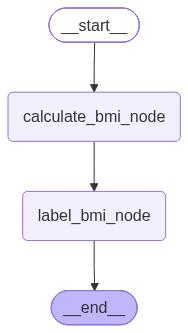

In [25]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())


In [ ]:
# add node to workflow after calculating bmi
# create label after calc bmi
